In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Read the image using OpenCV
# Your Code Here

image = cv2.imread(r"C:\Users\admin\Downloads\highway.png")

if image is None:
    raise FileNotFoundError("Image not found")

print("Image loaded successfully")

Image loaded successfully


In [3]:
# Convert to grayscale
# Your Code Here

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

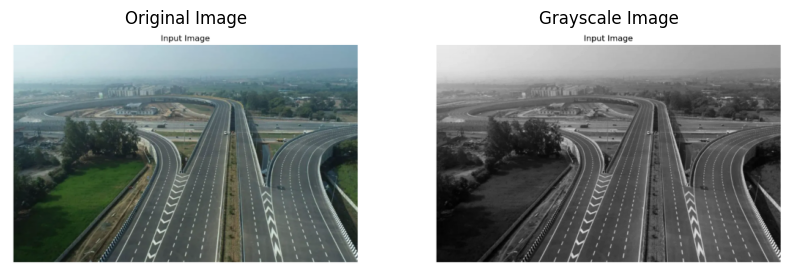

In [4]:
plt.figure(figsize=(10,5))

# Your Code Here

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')

plt.show()

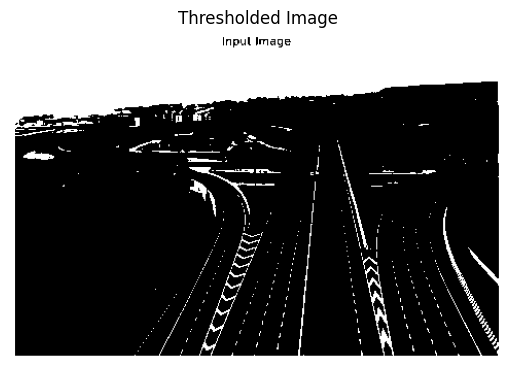

In [5]:
# Apply thresholding
# Your Code Here

threshold = cv2.threshold(gray_image, 150, 255, cv2.THRESH_BINARY)[1]

plt.imshow(threshold, cmap='gray')
plt.title("Thresholded Image")
plt.axis('off')
plt.show()

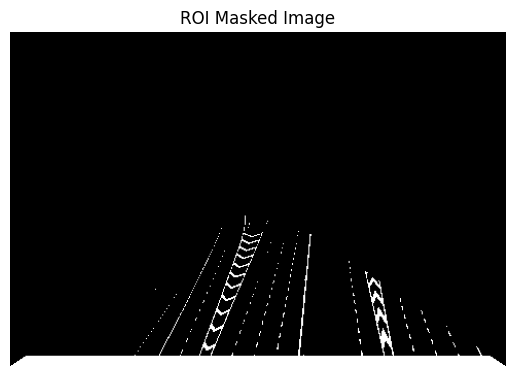

In [6]:
# ROI masking

height, width = threshold.shape

mask = np.zeros_like(threshold)

vertices = np.array([[
    (0, height - 1),
    (int(width * 0.45), int(height * 0.55)),
    (int(width * 0.55), int(height * 0.55)),
    (width - 1, height - 1)
]], dtype=np.int32)

cv2.fillPoly(mask, vertices, 255)

masked_image = cv2.bitwise_and(threshold, mask)

plt.imshow(masked_image, cmap='gray')
plt.title("ROI Masked Image")
plt.axis('off')
plt.show()

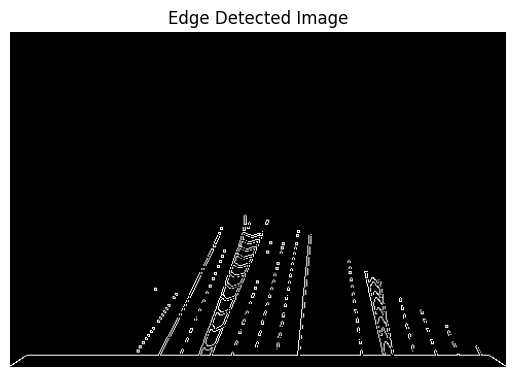

In [7]:
# Perform Edge Detection
# Your Code Here

edges = cv2.Canny(masked_image, 50, 150)

plt.imshow(edges, cmap='gray')
plt.title("Edge Detected Image")
plt.axis('off')
plt.show()

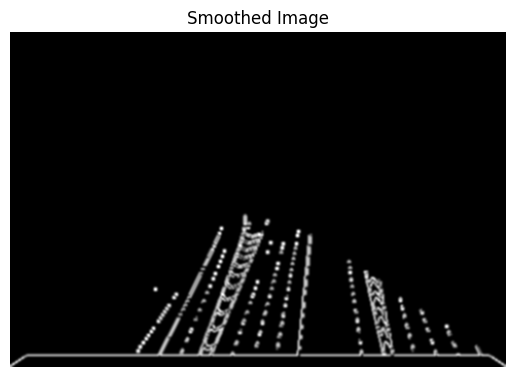

In [8]:
# Apply Gaussian Blur
# Your Code Here

blurred_image = cv2.GaussianBlur(edges, (5, 5), 0)

plt.imshow(blurred_image, cmap='gray')
plt.title("Smoothed Image")
plt.axis('off')
plt.show()

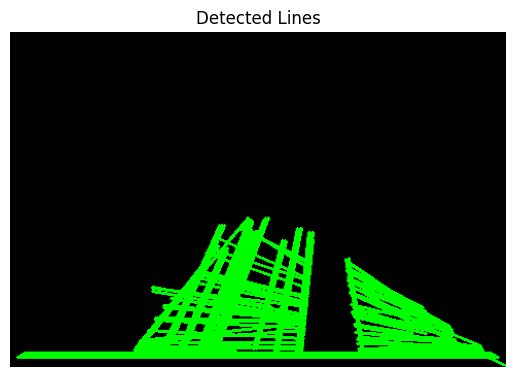

Number of detected lines: 106


In [9]:
# Detect lines using Hough Transform
# Your Code Here

lines = cv2.HoughLinesP(
    blurred_image,
    1,
    np.pi / 180,
    50,
    minLineLength=40,
    maxLineGap=20
)

line_image = np.zeros_like(image)

if lines is None:
    lines = np.empty((0, 1, 4), dtype=np.int32)

for line in lines:
    x1, y1, x2, y2 = line[0]
    cv2.line(line_image, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Lines")
plt.axis('off')
plt.show()

print("Number of detected lines:", len(lines))

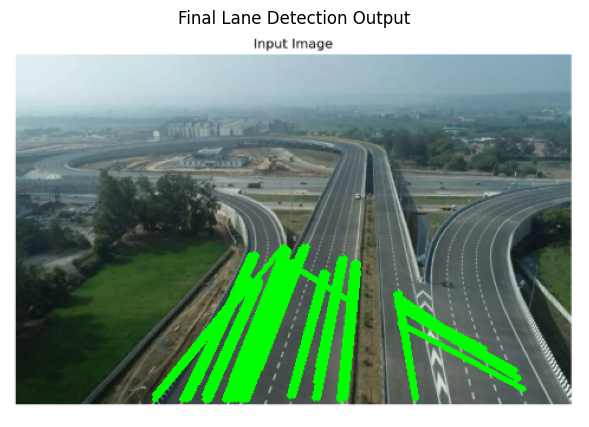

In [11]:
# Lane Detection Logic

final_image = image.copy()

for line in lines:
    x1, y1, x2, y2 = line[0]

    if abs(y2 - y1) > 0.5 * abs(x2 - x1):
        cv2.line(final_image, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.figure(figsize=(10,5))
plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
plt.title("Final Lane Detection Output")
plt.axis('off')
plt.show()